# 05. 다운샘플링 실험 — 셀별 실행

스크립트(`05_sampling_*.py`)의 함수를 그대로 부른다. 코드 수정은 `.py` 에서 하고 여기선 실행·확인만.

```
02 ×3 (구간별 피처)  →  select (방식 × 비율)  →  audit (통계)  →  통계 선별  →  LightGBM 빠른 비교(예정)  →  GNN train (추린 조건만)
```

**시간 분할** (월~일 주 단위, 11월 이후 미사용 — 11/6 부터 패턴 외 세탁 0건·정상 급감하는 생성기 꼬리 구간)

| 구간 | 기간 | 쓰임 |
|---|---|---|
| 학습 | 2022-08-08 ~ 10-02 (8주) | 학습 target. 8/1~8/7 은 그래프·이력에만 |
| 검증 | 2022-10-03 ~ 10-16 (2주) | 에폭·임계값 선택 |
| 테스트 | 2022-10-17 ~ 10-30 (2주) | 최종 후보만 한 번 평가 (`--eval-test`) |

**누수 방지** — 노드 피처와 adjacency(이웃 후보)는 각 구간 끝까지의 거래로만 만든다 (원 논문 방식).
학습 target 은 `features_train`(~10/02), 검증은 `features_val`(~10/16), 테스트는 `features_test`(~10/30) 의 그래프·피처를 쓴다.
엣지 피처는 원래 각 거래 직전까지만 보므로 구간과 무관하게 같다.
스크립트가 시작할 때 `features.json` 의 `context_end` 가 구간 끝과 같은지 확인하고 다르면 멈춘다.

실험 조건 = select(방식×비율) × apply(loss|struct) × reweight(none) × pi_eff × seed
- apply=loss : 그래프 유지, loss 에 넣는 정상 target 만 줄임 (지도 샘플링) / struct : adjacency 에서도 제거
- pi_eff : 손실에서 양성 가중치 비중. pos_weight 를 여기서 역산해 r 과 분리 (ipw 와 none 은 같은 목적함수 → none 만)

## 0. 설정

In [1]:
# !pip install --break-system-packages --no-cache-dir -q torch_geometric

In [2]:
import importlib, json, time, sys
from pathlib import Path
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

import sampling_lib as L
select  = importlib.import_module("05_sampling_select")
audit   = importlib.import_module("05_sampling_audit")
train   = importlib.import_module("05_sampling_train")
collect = importlib.import_module("05_sampling_collect")

THREADS, MEMORY = 8, "12GB"          # cgroup 한도 27GB — DuckDB 한도 + 파이썬 배열이 그 안에 들어야 함
TRAIN, VAL, TEST = L.TRAIN, L.VAL, L.TEST     # 2022-08-08:10-02 / 10-03:10-16 / 10-17:10-30
FEAT = L.FEAT                                 # {"train": "features_train", "val": "features_val", "test": "features_test"}

# 단계가 끝날 때마다 여기만 바꾼다 — 나머지 셀은 이 두 값으로 이름을 조합한다
R    = "10"                 # 정상:양성 비율
BEST = f"random_r{R}"       # 선별 후 최적 select 이름 (예: f"strata_r{R}_day-amount-cross_bank", f"hard_r{R}")
print("ROOT", L.ROOT); print("BASE", L.BASE); print("출력", L.SAMPLING)
print(f"학습 {TRAIN} / 검증 {VAL} / 테스트 {TEST}")
for f in ["transactions.parquet", "patterns.parquet"]:
    print(f"{'OK ' if (L.BASE/f).is_file() else '없음'} {f}")


ROOT /workspace/money_laundry_ai_
BASE /workspace/money_laundry_ai_/parquets/HI-Large
출력 /workspace/money_laundry_ai_/parquets/HI-Large/sampling
학습 2022-08-08:2022-10-02 / 검증 2022-10-03:2022-10-16 / 테스트 2022-10-17:2022-10-30
OK  transactions.parquet
OK  patterns.parquet


### 0-1. 구간별 피처 만들기 — `02_build_features.ipynb` 를 3번

`02` 의 설정 셀에서 아래 두 값만 바꿔 각각 전체 실행한다 (코드 수정 없음, 1회당 수십 분~1시간).

| TAG | CONTEXT_END | 출력 폴더 | 필요한 단계 |
|---|---|---|---|
| `"train"` | `"2022-10-02"` | `parquets/HI-Large/features_train/` | select(strata·cssmc)·audit·train — **먼저** |
| `"val"`   | `"2022-10-16"` | `parquets/HI-Large/features_val/`   | train (검증 예측) |
| `"test"`  | `"2022-10-30"` | `parquets/HI-Large/features_test/`  | train `--eval-test` (최종 후보만) |

통계 선별까지는 `features_train` 만 있으면 된다. 기존 `features/`(전체 기간, 누수 있음)는 이 실험에서 쓰지 않는다.

In [3]:
# 구간별 피처 준비 상태 — context_end 가 구간 끝과 같아야 한다
for split, win in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
    name = FEAT[split]; end = L.parse_window(win)[1]
    try:
        ce = L.features_context_end(name)
        print(f"{'OK ' if ce == end else '불일치'}  {name:15s} context_end={ce}  (구간 끝 {end})")
    except AssertionError:
        print(f"없음  {name:15s} → 02 를 TAG='{split}', CONTEXT_END='{end}' 로 실행")


OK   features_train  context_end=2022-10-02  (구간 끝 2022-10-02)
OK   features_val    context_end=2022-10-16  (구간 끝 2022-10-16)
OK   features_test   context_end=2022-10-30  (구간 끝 2022-10-30)


### 학습 구간 라벨 분포 — 일별 양성 수와 정상 수 (r 범위 정하는 근거)

In [4]:
con = L.connect(THREADS, MEMORY)
lab = L.load_labels(con, L.parse_window(TRAIN))
daily = lab.groupby("day").agg(pos=("y", "sum"), n=("y", "size"), unmatched=("in_pattern", lambda s: int(((lab.loc[s.index, "y"] == 1) & ~s).sum())))
daily["neg"] = daily.n - daily.pos; daily["neg_per_pos"] = (daily.neg / daily.pos).round(0)
print(f"학습 구간 {len(lab):,}건, 양성 {int(lab.y.sum()):,} (패턴 외 {int(daily.unmatched.sum()):,}), 정상 {int((lab.y==0).sum()):,}")
print(f"정상:양성 전체 = 1:{(lab.y==0).sum()/lab.y.sum():.0f}")
daily[["pos", "unmatched", "neg", "neg_per_pos"]].describe().round(0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

학습 구간 102,336,629건, 양성 110,671 (패턴 외 47,782), 정상 102,225,958
정상:양성 전체 = 1:924


,pos,unmatched,neg,neg_per_pos
count,56.0,56.0,56.0,56.0
mean,1976.0,853.0,1825464.0,942.0
std,367.0,114.0,870718.0,433.0
min,1190.0,623.0,826600.0,371.0
25%,1719.0,790.0,830112.0,615.0
50%,2090.0,859.0,1927566.0,853.0
75%,2291.0,938.0,1928655.0,1190.0
max,2547.0,1173.0,5377076.0,2111.0


## 1. 선택 (select) — 방식 × 비율 × 날짜별 예산 규칙

`select/<이름>/selected.parquet` 가 만들어진다. 이미 있으면 건너뛰므로 셀 전체를 다시 실행해도 된다.
양성은 항상 전부 포함. 적용 위치(지도/구조)·가중치는 여기서 정하지 않는다 — train 에서 정한다.

날짜별 예산 규칙 (`--budget`) — 전체 예산(양성 × r)은 같고 날짜에 나누는 방법만 다르다
- `pos` (기본): 그날 양성 수 × r. 날마다 정상:양성 = r:1, 정상이 많은 날은 보존율이 낮아짐 (일별 보존 편차 약 5.7배)
- `neg` (`_bneg`): 그날 정상 수 비율. 모든 날 보존율이 같아 날짜 비중이 모집단과 같음, 날별 정상:양성은 달라짐
- cssmc 는 군집 비례로 전체 예산을 나눠 날짜를 안 본다 (사실상 neg 와 같은 효과)

In [5]:
# 공통 인자 — 학습 구간과 학습 구간용 피처(features_train)
common = ["--train", TRAIN, "--features", FEAT["train"], "--threads", str(THREADS), "--memory", MEMORY]
S3, S5 = "day,amount,cross_bank", "day,amount,recent,cross_bank,new_pair"

for r in ["10", "30", "100"]:
    # 날짜별 예산 = 그날 양성 수 × r (기본, budget=pos)
    select.main(["--method", "random", "--ratio", r] + common)                                     # RUS (기준선)
    select.main(["--method", "strata", "--ratio", r, "--axes", S3] + common)                      # 다축 층화 3축
    select.main(["--method", "strata", "--ratio", r, "--axes", S5] + common)                      # 5축
    select.main(["--method", "hard",   "--ratio", r, "--hard-frac", "0.5"] + common)              # hard-negative 혼합
    select.main(["--method", "cssmc",  "--ratio", r, "--clusters", "30", "--candidates", "10"] + common)   # CSSMC (날짜 안 봄)

    # 날짜별 예산 = 전체 예산 × 그날 정상 수 비율 (budget=neg, 이름에 _bneg) — 날짜 비중을 모집단과 같게
    select.main(["--method", "random", "--ratio", r, "--budget", "neg"] + common)
    select.main(["--method", "strata", "--ratio", r, "--axes", S3, "--budget", "neg"] + common)
    select.main(["--method", "strata", "--ratio", r, "--axes", S5, "--budget", "neg"] + common)
    select.main(["--method", "hard",   "--ratio", r, "--hard-frac", "0.5", "--budget", "neg"] + common)

# 통계 참고용 (학습은 안 함): 샘플링 없음
# select.main(["--method", "none"] + common)


[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r10
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/strata_r10_day-amount-cross_bank
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/strata_r10_day-amount-recent-cross_bank-new_pair
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/hard_r10
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/cssmc_r10
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r10_bneg
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/strata_r10_day-amount-cross_bank_bneg
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/strata_r10_day-amount-recent-cross_bank-new_pair_bneg
[04:16:45] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/hard_r10_bneg
[04:16:45] 이미 있음: /workspace/money_la

### 선택 결과 확인 — 일별 양성/정상 수, IPW

In [6]:
name = f"random_r{R}"
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet")
print(json.dumps(json.loads((L.SAMPLING / "select" / name / "meta.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1))
sel.groupby("day").agg(pos=("y", "sum"), neg=("y", lambda s: int((s == 0).sum())), ipw_neg=("ipw", lambda s: float(s[sel.loc[s.index, "y"] == 0].mean()))).head(10)

{
 "method": "random",
 "ratio": 10.0,
 "train": "2022-08-08:2022-10-02",
 "seed": 42,
 "hard_frac": 0.5,
 "clusters": 30,
 "candidates": 10,
 "axes": null,
 "rows": 1217381,
 "pos": 110671,
 "neg": 1106710,
 "neg_population": 102225958,
 "ipw_sum_neg": 102225958.0,
 "daily_keep_min": 0.004736775154377584,
 "daily_keep_max": 0.026955769402249488,
 "seconds": 40.2
}


,pos,neg,ipw_neg
day,,,
2022-08-08,1190,11900,161.948067
2022-08-09,1227,12270,157.098126
2022-08-10,1300,13000,148.178923
2022-08-11,1349,13490,142.905263
2022-08-12,1410,14100,185.836028
2022-08-13,1278,12780,64.838967
2022-08-14,1305,13050,63.543678
2022-08-15,1519,15190,126.885319
2022-08-16,1594,15940,120.988896


## 2. 감사 (audit) — 학습 없이 통계로 비교

피처는 `edge_features.parquet` 에서 DuckDB 로 읽는다 (memmap 캐시 불필요). 선택 하나당 parquet 스캔 2회 + 집계 → 수 분.

In [7]:
audit.main(["--all", "--features", FEAT["train"], "--threads", str(THREADS), "--memory", MEMORY])

[04:16:46] 감사 있음: cssmc_r10
[04:16:46] 감사 있음: cssmc_r100
[04:16:46] 감사 있음: cssmc_r30
[04:16:46] 감사 있음: hard_r10
[04:16:46] 감사 있음: hard_r100
[04:16:46] 감사 있음: hard_r100_bneg
[04:16:46] 감사 있음: hard_r10_bneg
[04:16:46] 감사 있음: hard_r30
[04:16:46] 감사 있음: hard_r30_bneg
[04:16:46] 감사 있음: random_r10
[04:16:46] 감사 있음: random_r100
[04:16:46] 감사 있음: random_r100_bneg
[04:16:46] 감사 있음: random_r10_bneg
[04:16:46] 감사 있음: random_r30
[04:16:46] 감사 있음: random_r30_bneg
[04:16:46] 감사 있음: strata_r100_day-amount-cross_bank
[04:16:46] 감사 있음: strata_r100_day-amount-cross_bank_bneg
[04:16:46] 감사 있음: strata_r100_day-amount-recent-cross_bank-new_pair
[04:16:46] 감사 있음: strata_r100_day-amount-recent-cross_bank-new_pair_bneg
[04:16:46] 감사 있음: strata_r10_day-amount-cross_bank
[04:16:46] 감사 있음: strata_r10_day-amount-cross_bank_bneg
[04:16:46] 감사 있음: strata_r10_day-amount-recent-cross_bank-new_pair
[04:16:46] 감사 있음: strata_r10_day-amount-recent-cross_bank-new_pair_bneg
[04:16:46] 감사 있음: strata_r30_day-amount-cross_ban

In [8]:
import glob
A = pd.DataFrame({Path(p).parent.name: json.loads(open(p, encoding="utf-8").read()) for p in glob.glob(str(L.SAMPLING / "select" / "*" / "audit.json"))}).T
A["kl_raw"] = A.feature_raw.map(lambda d: d["kl_mean"]); A["kl_ipw"] = A.feature_ipw.map(lambda d: d["kl_mean"]); A["kl_max_feature"] = A.feature_raw.map(lambda d: d["kl_max_feature"])
A[["method", "ratio", "n_sel", "keep_rate", "kl_raw", "kl_ipw", "kl_max_feature", "daily_keep_ratio", "hour_jsd", "hard_frac_pop", "hard_frac_sel", "sibling_frac_pop", "sibling_frac_sel", "struct_pos_hop1_keep"]].round(5)

,method,ratio,n_sel,keep_rate,kl_raw,kl_ipw,kl_max_feature,daily_keep_ratio,hour_jsd,hard_frac_pop,hard_frac_sel,sibling_frac_pop,sibling_frac_sel,struct_pos_hop1_keep
hard_r100_bneg,hard,100.0,11067097,0.108261,0.00553,0.00001,sender_count_1h,1.00001,0.000228,0.24551,0.5,0.004259,0.008803,0.223905
random_r10_bneg,random,10.0,1106714,0.010826,0.00001,0.00001,sender_gap_minutes,1.000103,0.000002,0.24551,0.246346,0.004259,0.004231,0.015206
hard_r30_bneg,hard,30.0,3320132,0.032478,0.00557,0.00001,sender_count_1h,1.000033,0.000235,0.24551,0.5,0.004259,0.00884,0.070245
cssmc_r10,cssmc,10.0,1106709,0.010826,0.00001,0.00001,amt_z_pay_ccy,1.055298,0.000002,0.24551,0.245271,0.004259,0.004344,0.015158
strata_r10_day-amount-cross_bank,strata,10.0,1106701,0.010826,0.00586,0.00001,pair_history_count,5.690712,0.000378,0.24551,0.248953,0.004259,0.003913,0.01532
hard_r30,hard,30.0,3320130,0.032478,0.01294,0.00001,sender_count_1h,5.690743,0.001154,0.24551,0.5,0.004259,0.007978,0.070245
strata_r30_day-amount-cross_bank_bneg,strata,30.0,3320138,0.032478,0.00000,0.00000,pair_age_at_day_start,1.000173,0.000001,0.24551,0.245546,0.004259,0.004282,0.036731
random_r100_bneg,random,100.0,11067097,0.108261,0.00001,0.00001,pair_prior_count,1.00001,0.0,0.24551,0.245604,0.004259,0.004288,0.112218
strata_r10_day-amount-recent-cross_bank-new_pair,strata,10.0,1106687,0.010826,0.00588,0.00001,pair_history_count,5.690427,0.000386,0.24551,0.248791,0.004259,0.003909,0.015313
strata_r10_day-amount-cross_bank_bneg,strata,10.0,1106716,0.010826,0.00001,0.00001,pair_age_at_day_start,1.00025,0.000002,0.24551,0.245539,0.004259,0.004263,0.01517


### 2-1. 통계 선별 — 같은 r 에서 random 과 비교

| 방식 | 목적 | 통과 기준 (아래 셀 상수로 조정) |
|---|---|---|
| random | 기준선 | — |
| strata, cssmc | 분포 보존 | `kl_raw` 가 random 의 `KL_RATIO` 배 이하 · `kl_ipw` < `KL_IPW_MAX` · 일별 보존 편차가 random 의 `DAILY_RATIO` 배 이하 · 예산 채움 ≥ `FILL_MIN` |
| hard | 경계 보존 (분포를 일부러 바꿈) | 통계로 판단 불가 → `hard_frac_sel` ≈ 0.5 면 학습 후보 |

통계는 "모집단을 얼마나 닮았나"까지만 알려준다. 세탁 구분에 도움이 되는 정상을 남겼는지는 학습으로 확인한다.

In [9]:
KL_RATIO, KL_IPW_MAX, DAILY_RATIO, FILL_MIN = 0.7, 0.001, 2.0, 0.95

S = A[A.method != "none"].copy()
S["ratio"] = S.ratio.astype(float)
metas = {n: json.loads((L.SAMPLING / "select" / n / "meta.json").read_text(encoding="utf-8")) for n in S.index}
S["budget"] = [("cluster" if S.loc[n, "method"] == "cssmc" else metas[n].get("budget", "pos")) for n in S.index]
S["fill"] = [S.loc[n, "n_sel"] / (metas[n]["pos"] * metas[n]["ratio"]) for n in S.index]       # 선택 수 / 예산(양성 × r)

# 비교 기준: 같은 r 의 random. strata·hard 는 같은 예산 규칙의 random 과, cssmc 는 기본(pos) random 과 비교
rnd = {(x.ratio, x.budget): x for _, x in S[S.method == "random"].iterrows()}
def base_of(x): return rnd.get((x.ratio, x.budget if x.budget in ("pos", "neg") else "pos"))
S["kl_vs_random"]    = [S.loc[n, "kl_raw"] / base_of(S.loc[n]).kl_raw for n in S.index]
S["daily_vs_random"] = [S.loc[n, "daily_keep_ratio"] / base_of(S.loc[n]).daily_keep_ratio for n in S.index]
S["kl_vs_random_pos"] = [S.loc[n, "kl_raw"] / rnd[(S.loc[n, "ratio"], "pos")].kl_raw for n in S.index]   # 기본 RUS 대비

def verdict(x):
    if x.method == "random": return "기준선" if x.budget == "pos" else ("날짜 배분 효과 확인용 (pos 대비 KL " + f"{x.kl_vs_random_pos:.2f}배)")
    if x.method == "hard":
        return "학습 후보 (경계 보존)" if abs(x.hard_frac_sel - 0.5) < 0.05 else f"확인: hard 비율 {x.hard_frac_sel:.2f}"
    bad = [why for ok, why in [(x.kl_vs_random <= KL_RATIO, "KL 개선 부족"), (x.kl_ipw < KL_IPW_MAX, "IPW 복원 안 됨"),
                               (x.daily_vs_random <= DAILY_RATIO, "날짜 편향"), (x.fill >= FILL_MIN, "예산 미달")] if not ok]
    return "통과" if not bad else "탈락: " + ", ".join(bad)

S["판정"] = S.apply(verdict, axis=1)
cols = ["method", "budget", "ratio", "n_sel", "fill", "kl_raw", "kl_vs_random", "kl_vs_random_pos", "kl_ipw", "kl_max_feature",
        "daily_keep_ratio", "daily_vs_random", "hour_jsd", "hard_frac_pop", "hard_frac_sel", "sibling_frac_sel", "struct_pos_hop1_keep", "판정"]
S.sort_values(["ratio", "budget", "method"])[cols].round(5)


,method,budget,ratio,n_sel,fill,kl_raw,kl_vs_random,kl_vs_random_pos,kl_ipw,kl_max_feature,daily_keep_ratio,daily_vs_random,hour_jsd,hard_frac_pop,hard_frac_sel,sibling_frac_sel,struct_pos_hop1_keep,판정
cssmc_r10,cssmc,cluster,10.0,1106709,1.00000,0.00001,0.00103,0.00103,0.00001,amt_z_pay_ccy,1.055298,0.18544,0.000002,0.24551,0.245271,0.004344,0.015158,통과
hard_r10_bneg,hard,neg,10.0,1106714,1.00000,0.00553,794.02926,0.93746,0.00001,sender_count_1h,1.000103,1.00000,0.000222,0.24551,0.5,0.008649,0.026342,학습 후보 (경계 보존)
random_r10_bneg,random,neg,10.0,1106714,1.00000,0.00001,1.00000,0.00118,0.00001,sender_gap_minutes,1.000103,1.00000,0.000002,0.24551,0.246346,0.004231,0.015206,날짜 배분 효과 확인용 (pos 대비 KL 0.00배)
strata_r10_day-amount-cross_bank_bneg,strata,neg,10.0,1106716,1.00001,0.00001,0.79727,0.00094,0.00001,pair_age_at_day_start,1.00025,1.00015,0.000002,0.24551,0.245539,0.004263,0.01517,탈락: KL 개선 부족
strata_r10_day-amount-recent-cross_bank-new_pair_bneg,strata,neg,10.0,1106632,0.99993,0.00001,0.77766,0.00092,0.00001,pair_age_at_day_start,1.000926,1.00082,0.000002,0.24551,0.245356,0.004266,0.015161,탈락: KL 개선 부족
hard_r10,hard,pos,10.0,1106710,1.00000,0.01295,2.19427,2.19427,0.00001,sender_count_1h,5.690743,1.00000,0.001161,0.24551,0.5,0.007998,0.026342,학습 후보 (경계 보존)
random_r10,random,pos,10.0,1106710,1.00000,0.00590,1.00000,1.00000,0.00001,pair_history_count,5.690743,1.00000,0.000393,0.24551,0.249261,0.003824,0.015334,기준선
strata_r10_day-amount-cross_bank,strata,pos,10.0,1106701,0.99999,0.00586,0.99325,0.99325,0.00001,pair_history_count,5.690712,0.99999,0.000378,0.24551,0.248953,0.003913,0.01532,탈락: KL 개선 부족
strata_r10_day-amount-recent-cross_bank-new_pair,strata,pos,10.0,1106687,0.99998,0.00588,0.99610,0.99610,0.00001,pair_history_count,5.690427,0.99994,0.000386,0.24551,0.248791,0.003909,0.015313,탈락: KL 개선 부족
cssmc_r30,cssmc,cluster,30.0,3320128,1.00000,0.00001,0.00089,0.00089,0.00001,pair_prior_count,1.02745,0.18055,0.000001,0.24551,0.245587,0.004274,0.036736,통과


### 피처 분포 그림 — 모집단 vs 선택 정상 (KL 큰 피처 위주)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

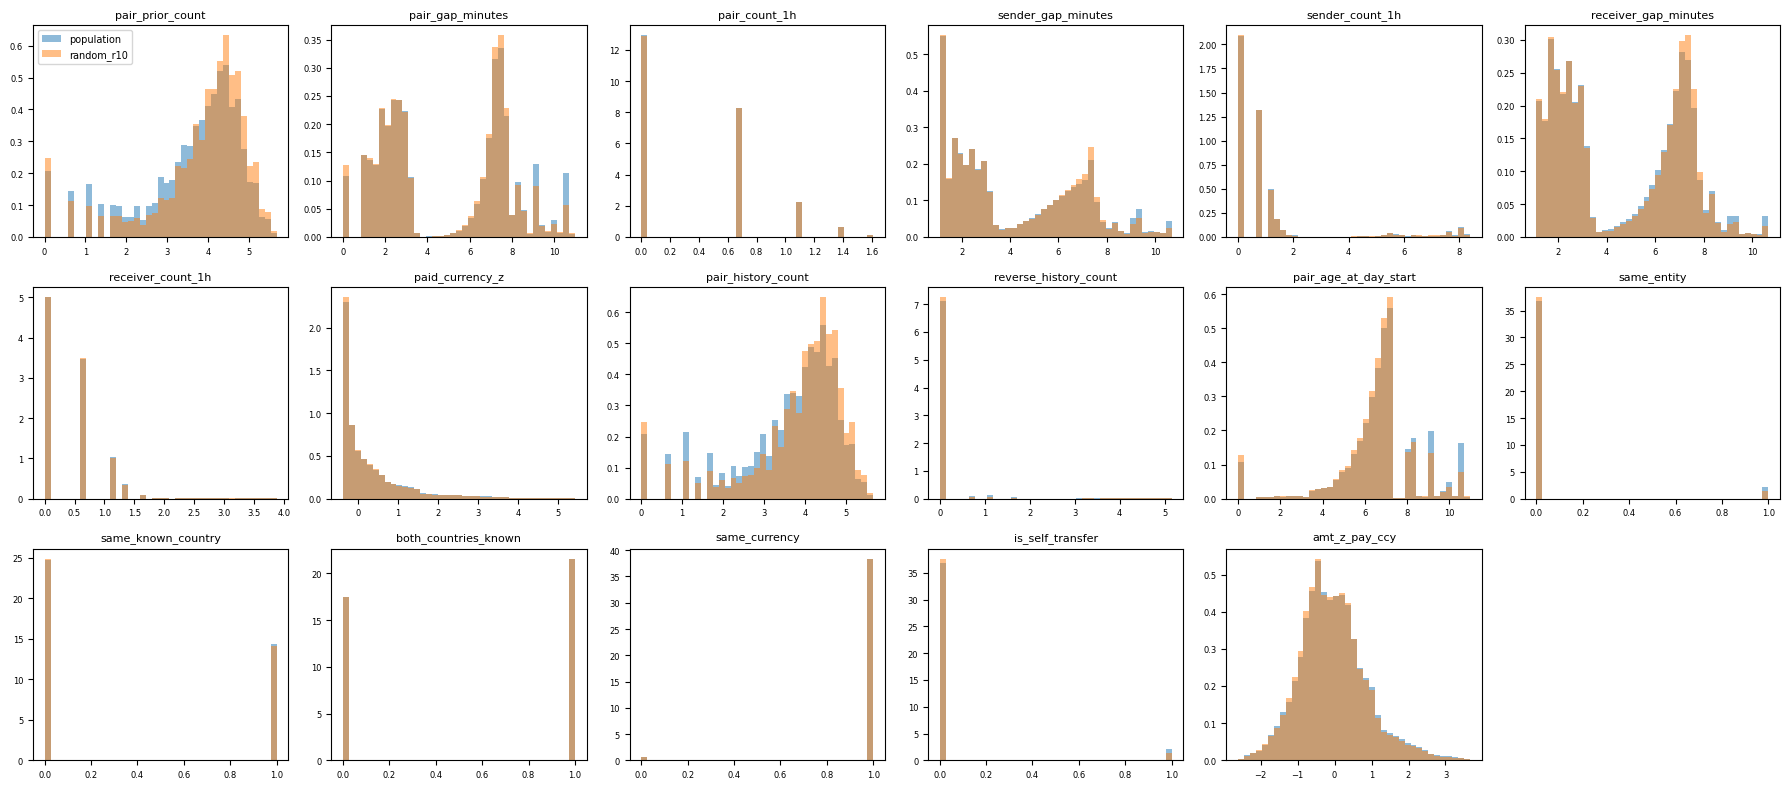

In [10]:
import matplotlib.pyplot as plt
name = f"random_r{R}"      # 다른 방식도 보려면 이름만 바꾼다 (예: f"cssmc_r{R}")
feat_dir = L.features_dir(FEAT["train"])
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet"); smp = sel[sel.y == 0]
pop_ids = np.sort(np.random.default_rng(0).choice(lab[lab.y == 0].edge_id.to_numpy(), 300_000, replace=False))
Xp, Xs = audit.read_features(con, feat_dir, pop_ids), audit.read_features(con, feat_dir, np.sort(smp.edge_id.to_numpy()[np.random.default_rng(0).choice(len(smp), min(len(smp), 300_000), replace=False)]))
fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for j, ax in enumerate(axes.ravel()[:17]):
    lo, hi = np.quantile(Xp[:, j], [0.001, 0.999]); bins = np.linspace(lo, hi, 40)
    ax.hist(Xp[:, j], bins, density=True, alpha=.5, label="population"); ax.hist(Xs[:, j], bins, density=True, alpha=.5, label=name)
    ax.set_title(L.EDGE_FEATURES[j], fontsize=8); ax.tick_params(labelsize=6)
axes.ravel()[0].legend(fontsize=7); axes.ravel()[17].axis("off"); fig.tight_layout(); plt.show()

## 3. 학습 (train) — 통계 선별·LightGBM 비교 뒤 추린 조건만

학습 target 은 `features_train` 그래프, 검증 target 은 `features_val` 그래프로 만든다 (구간별 GraphStore 캐시가 따로 생김, 각 수십 분 1회).
캐시 크기는 그 구간 끝까지의 거래 수만큼 (학습 약 8GB, 검증 약 9GB, 테스트 약 10GB). 예전 `cache/features/`(전체 기간)는 지워도 된다.
`run.json` 있으면 건너뛴다 (다시 돌리려면 `runs/<run_name>/` 삭제). 아래 두 셀은 학습이 끝난 뒤 결과 확인용.

In [11]:
# 완료된 실험 조건 전부 — run.json 요약 + 에폭별 검증 AP
import glob
runs = {}
for f in sorted(glob.glob(str(L.SAMPLING / "runs" / "*" / "run.json"))):
    r = json.loads(open(f, encoding="utf-8").read())
    runs[r["run_name"]] = dict(select=r["select"], apply=r["apply"], reweight=r["reweight"], pi_eff=r["pi_eff"], seed=r["seed"], pos_weight=round(r["pos_weight"], 2),
                               train_rows=r["train_rows"], epochs=r["epochs_run"], best_epoch=r["best_epoch"],
                               ms_per_target=round(r["train_sec_per_epoch"] / r["train_rows"] * 1000, 2), sec_per_epoch=round(r["train_sec_per_epoch"]),
                               gpu_gb=(round(r["gpu_peak_gb"], 1) if r["gpu_peak_gb"] else None), **{k: round(v, 4) for k, v in r["val"].items()})
summary = pd.DataFrame(runs).T
print(f"완료 {len(runs)}개 조건")
display(summary)

hist = pd.concat([pd.read_csv(Path(f).parent / "history.csv").assign(run=Path(f).parent.name) for f in glob.glob(str(L.SAMPLING / "runs" / "*" / "run.json"))], ignore_index=True) if runs else None
hist.pivot(index="epoch", columns="run", values="AP").round(4) if runs else None


완료 0개 조건


""


### 검증 점수 분포 — 완료된 조건 전부 (양성/정상 점수 히스토그램, F1 임계값)

/tmp/ipykernel_56779/1059771215.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].legend(fontsize=7); fig.tight_layout(); plt.show()


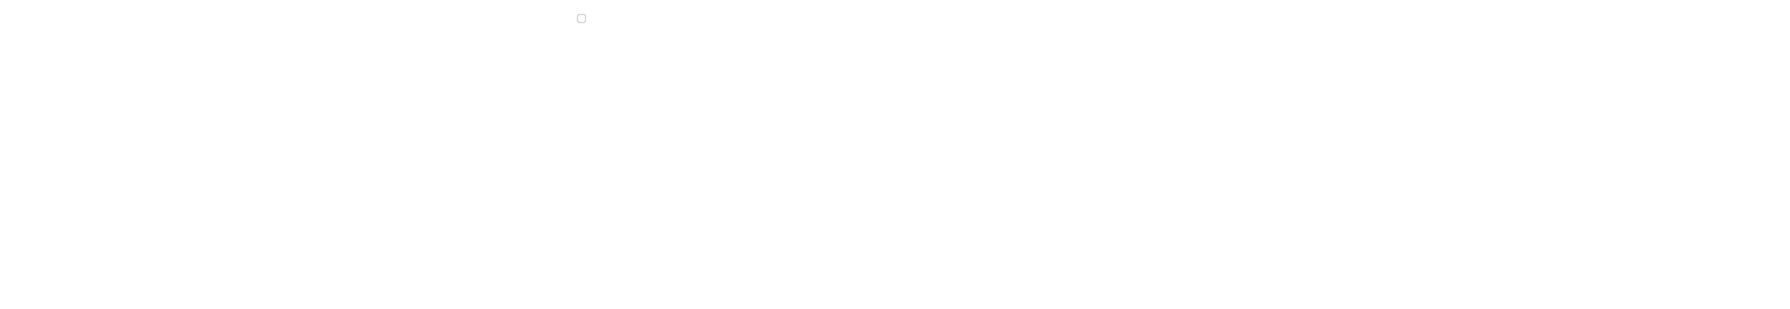

In [12]:
# 검증 점수 분포 — 조건별 양성/정상 히스토그램과 F1 임계값
names = list(runs); cols = 3; rows_ = max(1, -(-len(names) // cols))
fig, axes = plt.subplots(rows_, cols, figsize=(6 * cols, 3.2 * rows_), squeeze=False); bins = np.linspace(0, 1, 50)
for ax, name in zip(axes.ravel(), names):
    vs = pd.read_parquet(L.SAMPLING / "runs" / name / "val_scores.parquet")
    ax.hist(vs[vs.y == 0].score, bins, weights=vs[vs.y == 0].w, alpha=.5, label="normal (weighted)", log=True)
    ax.hist(vs[vs.y == 1].score, bins, alpha=.6, label="laundering", log=True)
    ax.axvline(runs[name]["threshold"], color="k", ls=":"); ax.set_title(f"{name}\nAP {runs[name]['AP']:.4f}  thr {runs[name]['threshold']:.3f}", fontsize=8); ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(names):]: ax.axis("off")
axes[0, 0].legend(fontsize=7); fig.tight_layout(); plt.show()


### 학습 조건 — 주석을 풀며 실행

이전 1차 결과(runs/ 의 random r10·r30·r100)는 누수 있는 피처·옛 분할로 학습한 것이라 **다시 돌려야 한다** — `runs/`, `val/`, `results/` 폴더를 지우고 시작.
최종 후보는 마지막에 `--eval-test` 를 붙여 테스트 구간을 한 번만 평가한다.

In [13]:
# 실험 조건 = (select 이름, apply, reweight, pi_eff, seed). run.json 있으면 건너뜀.
# 학습·검증 피처 폴더는 기본값(features_train / features_val)을 쓴다.
GRID = [
    # ── 비율 축 (RUS) ────────────────────────────────────────────────
    ("random_r10",  "loss", "none", 0.25, 42),
    ("random_r30",  "loss", "none", 0.25, 42),

    # ── 방식 축 (통계 선별 통과 + hard) ─────────────────────────────────
    # (f"strata_r{R}_day-amount-cross_bank",                 "loss", "none", 0.25, 42),
    # (f"strata_r{R}_day-amount-recent-cross_bank-new_pair", "loss", "none", 0.25, 42),
    # (f"hard_r{R}",                                         "loss", "none", 0.25, 42),
    # (f"cssmc_r{R}",                                        "loss", "none", 0.25, 42),

    # ── 양성 비중 축 (BEST 에서) ───────────────────────────────────────
    # (BEST, "loss", "none", 0.10, 42),
    # (BEST, "loss", "none", 0.50, 42),

    # ── 구조 샘플링 대조 (BEST 에서) ───────────────────────────────────
    # (BEST, "struct", "none", 0.25, 42),

    # ── 시드 반복 ────────────────────────────────────────────────────
    # (BEST, "loss", "none", 0.25, 43),
    # (BEST, "loss", "none", 0.25, 44),
]
EVAL_TEST = False     # 최종 후보를 돌릴 때만 True (테스트는 한 번만 본다)
for s, ap_, rw, pi, seed in GRID:
    train.main(["--select", s, "--apply", ap_, "--reweight", rw, "--pi-eff", str(pi), "--seed", str(seed),
                "--val", VAL, "--test", TEST, "--epochs", "6", "--patience", "2", "--batch", "32",
                "--threads", str(THREADS), "--memory", MEMORY] + (["--eval-test"] if EVAL_TEST else []))


[04:17:06] random_r10_loss_none_pi0.25_s42: target 1,217,381 (양성 110,671, 정상 1,106,710), 정상 가중치 합 1,106,710, pos_weight=3.33
[04:17:06] memmap 생성: edge 117,269,743 × 17, node 2,116,168 × 19, 기준 시점 2022-10-02 → /workspace/money_laundry_ai_/parquets/HI-Large/sampling/cache/features_train


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04:17:12]   edge 10,000,000/117,269,743


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04:17:17]   edge 20,000,000/117,269,743


...

[04:20:30]   edge 140,000,000/141,682,805
[04:20:31]   edge 141,682,805/141,682,805
[04:20:35]   노드 피처 2,109,821/2,116,168 계좌 (그 구간에 거래 없는 6,347개는 0)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04:21:54] GraphStore 준비 끝


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04:22:01] 검증 표본 생성: 양성 33,795 + 정상 487,587 → /workspace/money_laundry_ai_/parquets/HI-Large/sampling/val/2022-10-03_2022-10-16_neg0.02.parquet
[04:23:46]   epoch 1 0/1,217,381 loss 0.9324
[04:25:08]   epoch 1 6,400/1,217,381 loss 0.2917
[04:25:25]   epoch 1 12,800/1,217,381 loss 0.2033
[04:25:41]   epoch 1 19,200/1,217,381 loss 0.1903
[04:25:58]   epoch 1 25,600/1,217,381 loss 0.1578
[04:26:14]   epoch 1 32,000/1,217,381 loss 0.1798
[04:26:30]   epoch 1 38,400/1,217,381 loss 0.1722
[04:26:47]   epoch 1 44,800/1,217,381 loss 0.1874
[04:27:04]   epoch 1 51,200/1,217,381 loss 0.1641
[04:27:21]   epoch 1 57,600/1,217,381 loss 0.1760
[04:27:37]   epoch 1 64,000/1,217,381 loss 0.1619
[04:27:54]   epoch 1 70,400/1,217,381 loss 0.1804
[04:28:11]   epoch 1 76,800/1,217,381 loss 0.1647
[04:28:28]   epoch 1 83,200/1,217,381 loss 0.1920
[04:28:45]   epoch 1 89,600/1,217,381 loss 0.2003
[04:29:01]   epoch 1 96,000/1,217,381 loss 0.1742
[04:29:17]   epoch 1 102,400/1,217,381 loss 0.1778
[04:29:34] 

## 4. 합치기 (collect) — 통계 감사 + 모델 지표 한 표

=== 선택 결과 통계 감사 (학습 무관) ===
                                                         kl_raw   kl_ipw  psi_raw  daily_keep_ratio  hour_jsd  hard_frac_sel  hard_frac_pop  struct_pos_hop1_keep
select                                                                                                                                                           
hard_r100_bneg                                          0.00553  0.00001  0.01168           1.00001   0.00023        0.50000        0.24551               0.22390
random_r10_bneg                                         0.00001  0.00001  0.00001           1.00010   0.00000        0.24635        0.24551               0.01521
hard_r30_bneg                                           0.00557  0.00001  0.01178           1.00003   0.00024        0.50000        0.24551               0.07024
cssmc_r10                                               0.00001  0.00001  0.00001           1.05530   0.00000        0.24527        0.24551               0.01516


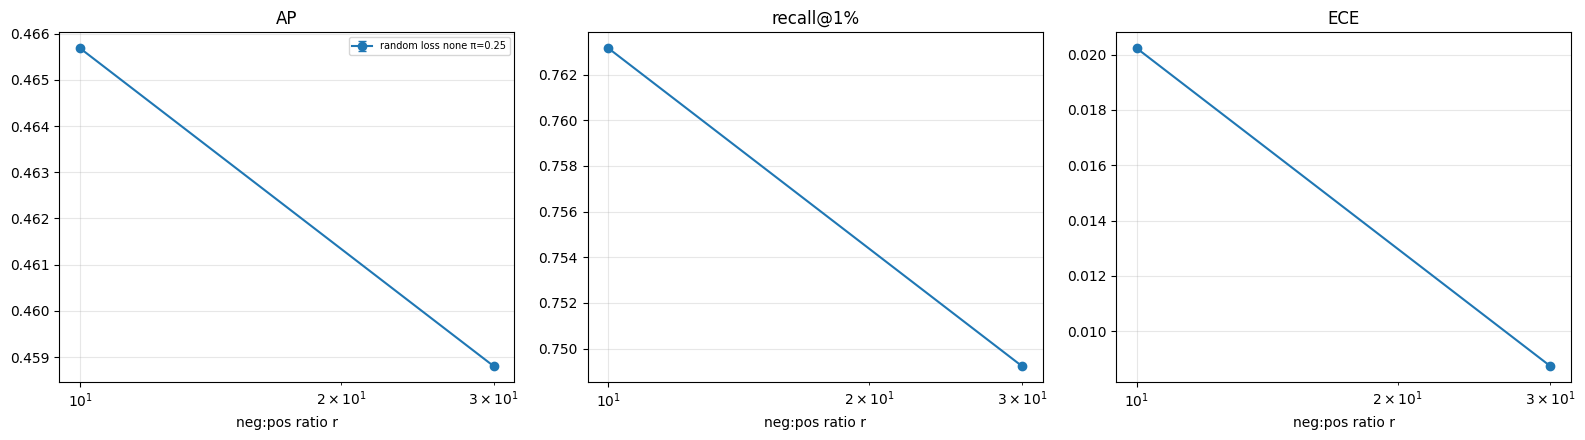

,run_name,method,ratio,apply,reweight,pi_eff,pos_weight,train_rows,AP,F1,recall_at_1pct,unmatched_recall_at_1pct,ECE,kl_raw,daily_keep_ratio,hard_frac_sel,train_sec_per_epoch,gpu_peak_gb
0,random_r10_loss_none_pi0.25_s42,random,10.0,loss,none,0.25,3.3333,1217381,0.4657,0.5144,0.7632,0.4413,0.0202,0.0059,5.6907,0.2493,4408.1667,1.5385
1,random_r30_loss_none_pi0.25_s42,random,30.0,loss,none,0.25,10.0000,3430801,0.4588,0.5375,0.7492,0.4221,0.0087,0.0058,5.6907,0.2488,10581.0000,1.5385


In [14]:
df, summ = collect.main()
df[["run_name", "method", "ratio", "apply", "reweight", "pi_eff", "pos_weight", "train_rows", "AP", "F1", "recall_at_1pct", "unmatched_recall_at_1pct", "ECE",
    "kl_raw", "daily_keep_ratio", "hard_frac_sel", "train_sec_per_epoch", "gpu_peak_gb"]].sort_values(["method", "ratio", "apply", "reweight"]).round(4) if df is not None else None


## 판단 기준 (메모)

1. 통계 선별: strata·cssmc 는 같은 r 의 random 보다 `kl_raw` 가 확실히 작아야 학습할 가치가 있다. hard 는 통계로 거르지 않는다
2. 학습 비교는 순위 지표(AP, recall@1%, 패턴 외 recall@1%)로. ECE·threshold 는 정상을 줄인 만큼 확률이 부풀려져 조건 간 비교 불가
3. 같은 r·pi_eff 에서 방식 간 AP 차이가 에폭 간 흔들림(±0.05)보다 작으면 "차이 없음" — 시드 반복으로 확인
4. 테스트(`--eval-test`)는 최종 후보에만, 한 번만

In [15]:
# 배치 내 target 이웃 겹침 측정 — 학습 그래프(features_train) + random_r10 선택 결과
store = L.GraphStore(FEAT["train"], None, THREADS, MEMORY); store.prepare(); store.load()   # 캐시 있으면 로드만
sel = pd.read_parquet(L.SAMPLING / "select" / f"random_r{R}" / "selected.parquet")

def edges_of(e):
    """target e 의 2홉 서브그래프 간선 id (build 와 같은 규칙)"""
    s, d = int(store.edge_src[e]), int(store.edge_dst[e])
    e1, i1, o1 = store._select(np.unique([s, d]))
    nb = np.unique(np.r_[np.asarray(store.edge_src[e1])[i1], np.asarray(store.edge_dst[e1])[o1]])
    return np.unique(np.r_[e1, store._select(nb)[0]])

rng = np.random.default_rng(0)
ids_ = sel.edge_id.to_numpy(); pos = set(sel.edge_id[sel.y == 1].tolist())
tot = uni = n_pos = n_hit = 0; t = time.time()
for _ in range(100):                                   # 무작위 배치 100개 (학습과 같은 크기 32)
    b = ids_[rng.choice(len(ids_), 32, replace=False)]
    es = {int(e): edges_of(int(e)) for e in b}
    tot += sum(len(v) for v in es.values()); uni += len(np.unique(np.concatenate(list(es.values()))))
    bpos = set(es) & pos
    for e in bpos:                                     # 양성 target 의 2홉 안에 같은 배치의 다른 양성 target 이 있나
        others = bpos - {e}
        if others:
            n_pos += 1; n_hit += bool(others & set(es[e].tolist()))
print(f"① 간선 중복 비율 (union 이 줄여줄 몫): {1 - uni / tot:.4f}   (배치당 간선 {tot/100:,.0f} → union {uni/100:,.0f})")
print(f"② 다른 양성과 같은 배치인 양성 {n_pos}건 중, 그 양성이 2홉 안에 있는 비율: {n_hit / max(n_pos, 1):.4f}")
print(f"소요 {time.time() - t:.0f}초  (3,200 target)")

[01:23:53] GraphStore 캐시 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/cache/features_train
① 간선 중복 비율 (union 이 줄여줄 몫): 0.1293   (배치당 간선 93,033 → union 81,008)
② 다른 양성과 같은 배치인 양성 294건 중, 그 양성이 2홉 안에 있는 비율: 0.0000
소요 6초  (3,200 target)


In [16]:
import torch
device = "cuda"; model = L.make_model(3.33).to(device); model.train()
b_ids = ids_[rng.choice(len(ids_), 32 * 20, replace=False)]
t = time.time(); bs = [store.collate(b_ids[i:i + 32], "cpu") for i in range(0, len(b_ids), 32)]; t_cpu = (time.time() - t) / 20
model(*[x.to(device) for x in bs[0]]).sum().backward(); torch.cuda.synchronize()     # 워밍업
t = time.time()
for b in bs: model(*[x.to(device) for x in b]).sum().backward()
torch.cuda.synchronize(); t_gpu = (time.time() - t) / 20
print(f"조립 {t_cpu*1000:.0f} ms/배치, GPU(전송+forward+backward) {t_gpu*1000:.0f} ms/배치 → 워커 약 {t_cpu / t_gpu:.1f}개면 GPU 가 병목")
import os; print("CPU 코어", os.cpu_count())

조립 96 ms/배치, GPU(전송+forward+backward) 25 ms/배치 → 워커 약 3.8개면 GPU 가 병목
CPU 코어 80
